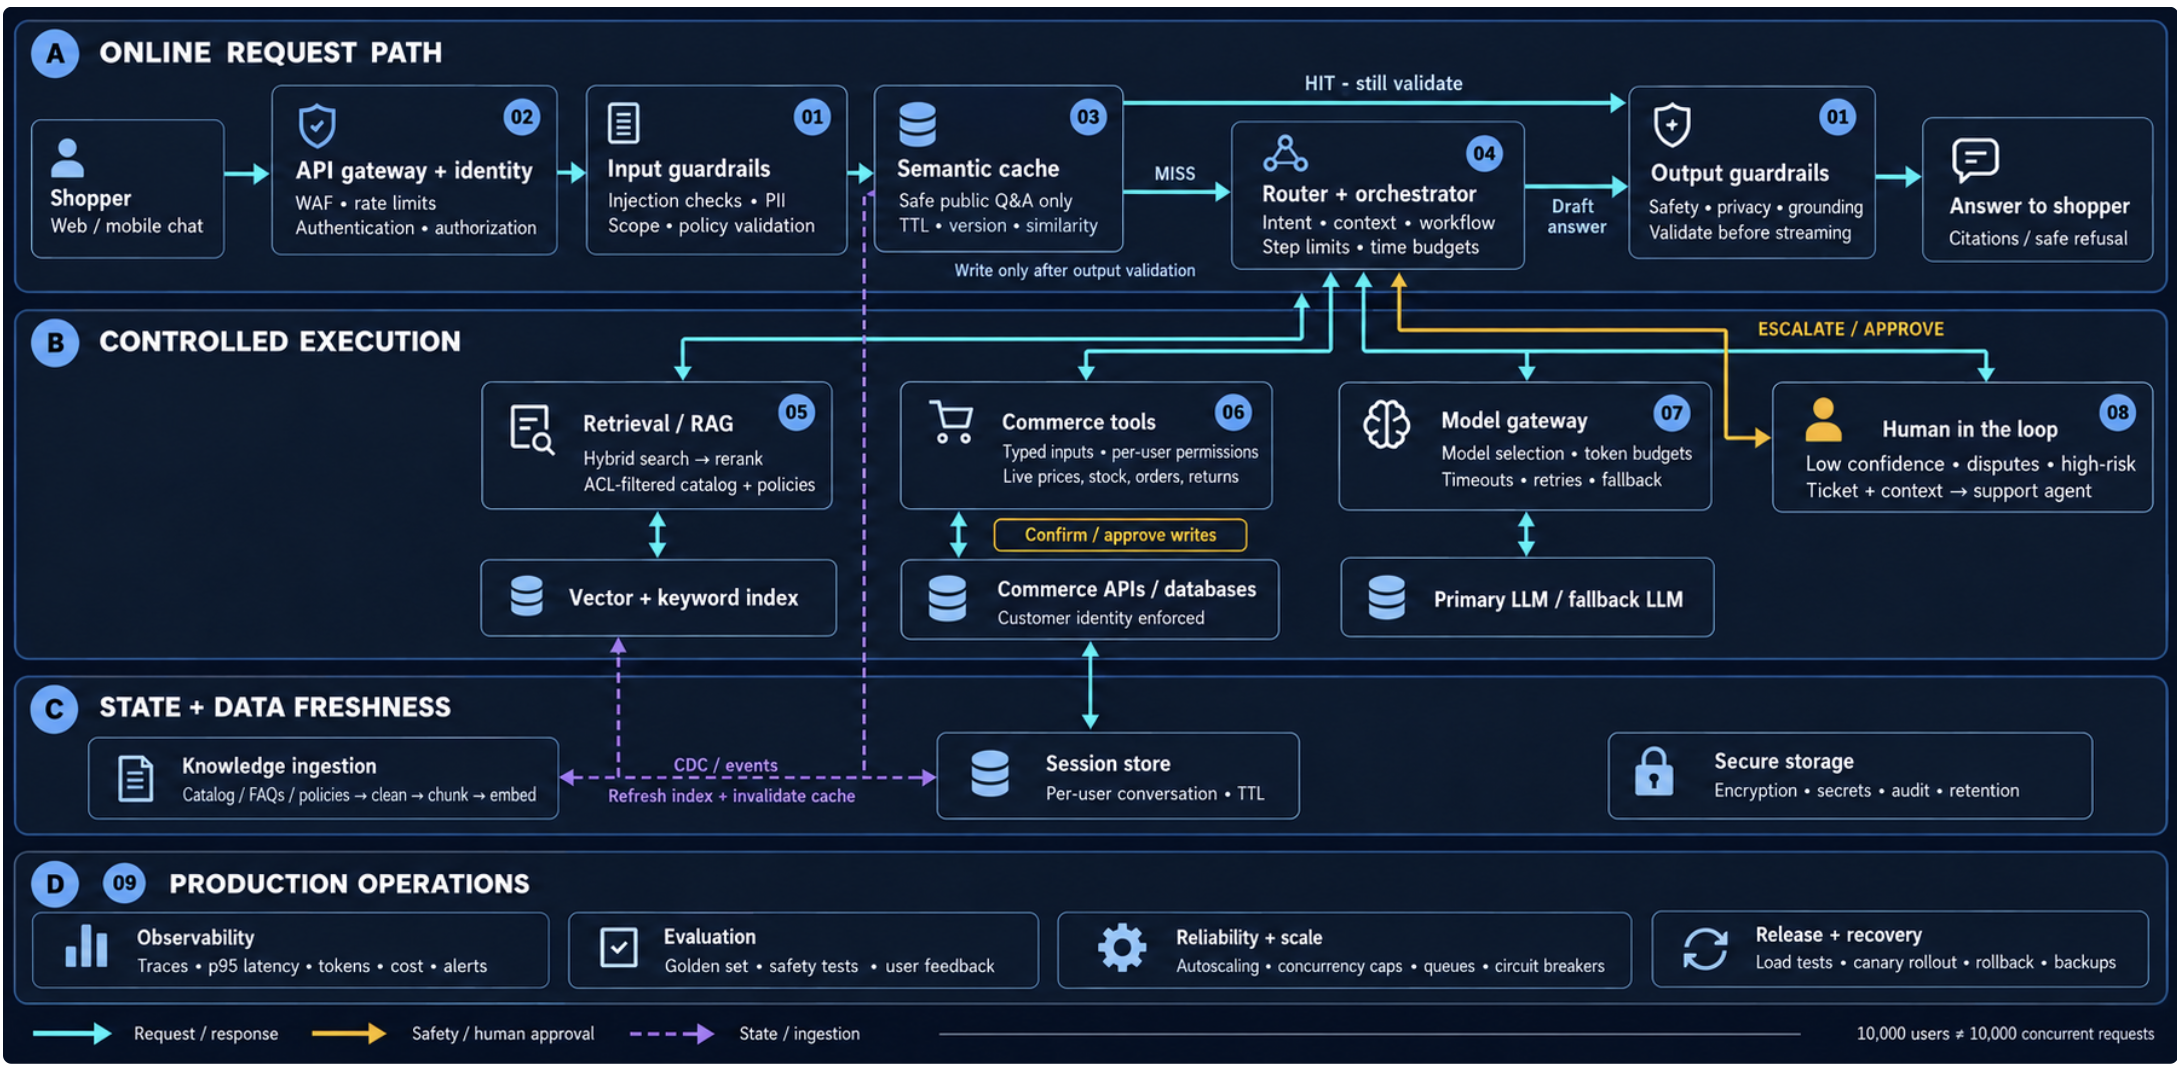

# AWS Bedrock production architecture — step-by-step

Your diagram represents an enterprise shopping assistant with RAG, LLMs, commerce APIs, human approval, security, and production monitoring. Below is the step name, purpose in a few words, and recommended AWS technology for each component.

## A. Online request path

| Step | Component              | Purpose in a few words              | AWS technology                                                  |
| ---- | ---------------------- | ----------------------------------- | --------------------------------------------------------------- |
| 1    | Shopper UI             | Customer asks a question            | Angular + Amazon CloudFront + Amazon S3                         |
| 2    | API Gateway + Identity | Authenticate, authorize, rate-limit | Amazon API Gateway + Amazon Cognito + AWS WAF                   |
| 3    | Input Guardrails       | Detect injection, PII, unsafe input | Amazon Bedrock Guardrails + AWS Lambda                          |
| 4    | Semantic Cache         | Reuse safe, validated answers       | Amazon ElastiCache for Valkey/Redis; DynamoDB for metadata      |
| 5    | Router + Orchestrator  | Select agent and manage workflow    | LangGraph + Amazon Bedrock AgentCore Runtime, or AWS Lambda/ECS |
| 6    | Output Guardrails      | Validate safety, privacy, grounding | Amazon Bedrock Guardrails + application validation              |
| 7    | Answer to Shopper      | Return answer with citations        | FastAPI + API Gateway response streaming                        |

Request flow: Customer → API Gateway → input validation → semantic cache → orchestration → output validation → customer response.

If the cache misses, the orchestrator runs the required tools and agents. Cache entries should be written only after output validation.

## B. Controlled execution — agents and tools

| Step | Component                  | Purpose in a few words                        | AWS technology / framework                                                      |
| ---- | -------------------------- | --------------------------------------------- | ------------------------------------------------------------------------------- |
| 8    | Retrieval / RAG            | Find relevant policies and product details    | Amazon Bedrock Knowledge Bases or custom LangChain RAG                          |
| 9    | Vector + Keyword Index     | Store embeddings and searchable text          | Amazon OpenSearch Serverless; Amazon S3 for source documents                    |
| 10   | Commerce Tools             | Read orders, prices, stock, returns           | Amazon Bedrock AgentCore Gateway + MCP tools + AWS Lambda                       |
| 11   | Commerce APIs / Databases  | Fetch or update live business data            | Amazon API Gateway + Lambda/ECS + Amazon Aurora or DynamoDB                     |
| 12   | Model Gateway              | Select LLM, control retries and fallback      | Amazon Bedrock Converse API + application-level routing                         |
| 13   | Primary LLM / Fallback LLM | Generate responses and recover from failures  | Amazon Bedrock models, such as Amazon Nova or supported Anthropic Claude models |
| 14   | Human in the Loop          | Approve high-risk actions or resolve disputes | LangGraph interrupt/resume + Amazon SQS or Step Functions + support UI          |

For retrieval, you can use Amazon Bedrock Knowledge Bases for a managed RAG pipeline, or build custom retrieval with LangChain, embeddings, OpenSearch, and a reranker.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://docs.aws.amazon.com\&sz=32)

Amazon Bedrock

+1



Important: A model should not directly update orders or issue refunds without authorization and business-rule checks. Require explicit approval for sensitive writes where appropriate.

## C. State and data freshness

| Component               | Purpose in a few words                     | AWS technology                                            |
| ----------------------- | ------------------------------------------ | --------------------------------------------------------- |
| 15. Knowledge ingestion | Parse, clean, chunk and embed documents    | Amazon S3 + AWS Lambda / ECS + Amazon Bedrock embeddings  |
| 16. Session store       | Maintain conversation and workflow state   | Amazon Bedrock AgentCore Memory or DynamoDB               |
| 17. CDC / Events        | Refresh indexes and invalidate stale cache | Amazon EventBridge + Amazon SQS; AWS DMS for database CDC |
| 18. Secure storage      | Encrypt secrets and protect audit data     | AWS KMS + AWS Secrets Manager + CloudTrail + S3           |

For example, when a return policy changes, the ingestion pipeline updates the searchable index and invalidates affected cached answers. For an order-status query, fetch current data from the commerce API rather than relying on an old cached response.

Amazon Bedrock AgentCore Memory is useful for conversation context; DynamoDB is a strong option for application-owned session state, TTLs, and structured workflow records.

## D. Production operations

| Component                 | Purpose in a few words                           | AWS technology                                                             |
| ------------------------- | ------------------------------------------------ | -------------------------------------------------------------------------- |
| 19. Observability         | Trace requests, tokens, cost, latency and errors | Amazon CloudWatch + AWS X-Ray / OpenTelemetry                              |
| 20. Evaluation            | Measure retrieval, correctness and safety        | Amazon Bedrock evaluations + custom evaluation datasets                    |
| 21. Reliability and scale | Handle concurrency and traffic spikes            | AgentCore Runtime + ECS/Fargate or Lambda + SQS + Application Auto Scaling |
| 22. Release and recovery  | Test, deploy, roll back and restore              | AWS CodePipeline / GitHub Actions + ECR + CDK/CloudFormation + AWS Backup  |

AgentCore provides runtime hosting and agent-specific observability, including metrics and traces that can be viewed in CloudWatch.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://docs.aws.amazon.com\&sz=32)

Amazon Bedrock AgentCore

+1



## Recommended deployment architecture

Frontend

Angular · S3 · CloudFront

Security and API layer

AWS WAF · Cognito · API Gateway

Agent execution

Amazon Bedrock AgentCore Runtime

Python · LangGraph · LangChain

LLM

Amazon Bedrock

Tools

AgentCore Gateway · MCP

RAG

S3 · OpenSearch

Application data

Aurora · DynamoDB

Cross-cutting services

Bedrock Guardrails · AgentCore Identity and Memory · CloudWatch · KMS · Secrets Manager · CI/CD

This is a recommended reference design. Choose services based on workload, security requirements, existing infrastructure, and cost.

## Which services should you prioritize?

For an interview, remember these five core technology choices:

1. Agent framework: Python + LangGraph + LangChain.
2. AI platform: Amazon Bedrock for LLM inference and Guardrails.
3. Agent hosting and tools: AgentCore Runtime + Gateway + Identity.
4. RAG: S3 + Bedrock Knowledge Bases or custom OpenSearch-based retrieval.
5. Production operations: API Gateway + IAM/Cognito + CloudWatch + CI/CD.

Official reference: [Amazon Bedrock AgentCore documentation](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/what-is-bedrock-agentcore.html?utm_source=chatgpt.com).

Interview tip: If asked how you would build this for 10,000 users, explain that 10,000 registered users do not necessarily mean 10,000 concurrent requests. Estimate peak concurrency, load-test the full request path, configure quotas and scaling, and measure p95 latency, error rate, token usage and cost before committing to capacity.

LLM inference is the process of running a trained language model to generate predictions (like text) from new input. It's the "using" phase, as opposed to training, where the model applies its learned weights to produce outputs token by token.